[Download this notebook](lasso_vs_ols_simulated_fa26.ipynb){download="lasso_vs_ols_simulated_fa26.ipynb"} to run the code or borrow from it.

**The question.** One input is an exact combination of the other two: $x_3 = 2x_1 + 3x_2$. What do OLS and LASSO do with it?

- **OLS** minimizes $\text{RSS}$.
- **LASSO** minimizes $\text{RSS} + \lambda \sum_j |\beta_j|$. Its penalty shrinks coefficients and sets some to exactly 0.

**The short answer.** They predict almost equally well but tell different stories. Median test $R^2$ was 0.839 for OLS and 0.838 for LASSO, and LASSO won only 24 of 50 simulated datasets. OLS spreads the effect across all three inputs, while LASSO puts nearly all of it on $x_3$.

This is the opposite of the [Ames notebook](lasso_vs_ols_ames_fa26.html), where LASSO clearly won. The difference is explained in Part 6.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, LassoCV, LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BLUE, ORANGE, GREEN, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True, "legend.frameon": False})
INPUTS = ["x1", "x2", "x3"]


def simulate(n=100, seed=1, b1=4, b2=6, noise_sd=3):
    """x1 and x2 are independent. x3 is an exact combination of them. y depends on x1, x2 and noise."""
    rng = np.random.default_rng(seed)
    x1, x2 = rng.normal(size=n), rng.normal(size=n)
    y = 5 + b1 * x1 + b2 * x2 + rng.normal(scale=noise_sd, size=n)
    return pd.DataFrame({"x1": x1, "x2": x2, "x3": 2 * x1 + 3 * x2}), pd.Series(y, name="y")


def scores(model, X, y):
    """Return R-squared and RMSE of a fitted model on the data given."""
    pred = model.predict(X)
    return r2_score(y, pred), mean_squared_error(y, pred) ** 0.5


X, y = simulate()

# Part 1. Introduce the dataset

We simulate the data, so we know exactly how it was made. Each row is one simulated observation, and we predict `y`, so this is a regression problem.

| Variable | How it is made |
|:--|:--|
| `x1` | Random draw from a standard normal distribution |
| `x2` | Random draw from a standard normal distribution, independent of `x1` |
| `x3` | $2x_1 + 3x_2$, with no noise |
| `y` | $5 + 4x_1 + 6x_2 + \varepsilon$, where $\varepsilon$ is normal with SD 3 |

Because $4x_1 + 6x_2 = 2x_3$, the same `y` can also be written $y = 5 + 2x_3 + \varepsilon$. So there's no single "true" set of coefficients for the three inputs. This matters for everything below.

In [2]:
print("Rows:", X.shape[0], " Inputs:", X.shape[1])
pd.concat([X, y], axis=1).head().round(3)

Rows: 100  Inputs: 3


,x1,x2,x3,y
0,0.346,-0.651,-1.263,7.960
1,0.822,0.862,4.231,19.521
2,0.330,-0.126,0.284,2.374
3,-1.303,0.669,-0.599,4.921
4,0.905,1.219,5.467,13.915


In [3]:
print("Largest |x3 - 2*x1 - 3*x2|:", np.abs(X.x3 - 2 * X.x1 - 3 * X.x2).max())
print("Columns:", X.shape[1], "  Independent columns (matrix rank):", np.linalg.matrix_rank(X.values))
print("\nCorrelations:")
print(pd.concat([X, y], axis=1).corr().round(3).to_string())

Largest |x3 - 2*x1 - 3*x2|: 8.881784197001252e-16
Columns: 3   Independent columns (matrix rank): 2

Correlations:
       x1     x2     x3      y
x1  1.000 -0.027  0.479  0.442
x2 -0.027  1.000  0.865  0.801
x3  0.479  0.865  1.000  0.926
y   0.442  0.801  0.926  1.000


The checks confirm the setup:

- **`x3` adds no new information.** The difference from $2x_1 + 3x_2$ is only rounding error, so the three columns contain just 2 independent columns (matrix rank 2).
- **`x3` tracks `y` most closely** among the inputs, with correlation 0.926, compared with 0.801 for `x2` and 0.442 for `x1`.
- **`x1` and `x2` are nearly uncorrelated** in this sample (−0.027), as designed.

# Part 2. Explain the testing procedure

The same procedure is used for both models, so the contest is fair.

| Step | What happens | Why |
|:--|:--|:----|
| 1. Simulate | Draw 100 new rows | Each dataset is a fresh sample from the same process |
| 2. Split | Randomly assign 70% of rows to training and 30% to test | The test set shows performance on rows the model hasn't seen |
| 3. Standardize | Learn each input's mean and SD from the training rows only, then apply them to the test rows | The LASSO penalty treats inputs on the same scale, with no test information leaking in |
| 4. Fit OLS | Fit on the training rows | There is nothing to tune |
| 5. Tune and fit LASSO | Choose `alpha` by 5-fold cross-validation **within the training rows**, then refit | The test set plays no part in choosing `alpha` |
| 6. Score | Compute test $R^2$ and RMSE for both models | Same test rows for both, so any difference comes from the models |
| 7. Repeat | Run steps 1 to 6 on **50 simulated datasets** (seeds 1 to 50) | One dataset can be lucky |

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
print("Training rows:", len(X_train), "  Test rows:", len(X_test))

Training rows: 70   Test rows: 30


# Part 3. OLS results, tuning alpha, and LASSO coefficients

This part walks through a single dataset (`seed=1`). Part 4 repeats everything on all 50.

## 3a. OLS

In [5]:
ols = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
print("OLS train R2 = %.3f, RMSE = %.2f" % scores(ols, X_train, y_train))
print("OLS test  R2 = %.3f, RMSE = %.2f" % scores(ols, X_test, y_test))

ols_coef = pd.Series(ols[-1].coef_, index=INPUTS)
print("\nOLS coefficients (per 1 SD of each input):")
print(ols_coef.round(3).to_string())

OLS train R2 = 0.893, RMSE = 2.46
OLS test  R2 = 0.750, RMSE = 3.31

OLS coefficients (per 1 SD of each input):
x1    1.735
x2    3.099
x3    3.633


The usual OLS formula, $\hat\beta = (X^TX)^{-1}X^Ty$, fails here: with rank 2, $X^TX$ has no inverse. So OLS has **no unique solution**. `LinearRegression` still returns an answer because it uses a method that picks one solution, the one with the smallest sum of squared coefficients.

The next table shows that other coefficients fit exactly as well. Each row removes one input by setting its coefficient to 0.

In [6]:
# All OLS solutions lie on one line: start from the sklearn answer and move along the direction
# that leaves the predictions unchanged (the null space of the standardized inputs).
Z_train = pd.DataFrame(ols[0].transform(X_train), columns=INPUTS)
null_dir = np.linalg.svd(Z_train.values)[2][-1]
null_dir = null_dir / null_dir[2]             # scale it so the x3 coefficient moves by exactly 1


def solution_with_x3(c):
    """The OLS solution whose x3 coefficient equals c."""
    return ols_coef.values + (c - ols_coef["x3"]) * null_dir


# Force each coefficient to 0 in turn, which gives three more solutions
c_zero_x1 = ols_coef["x3"] - ols_coef["x1"] / null_dir[0]
c_zero_x2 = ols_coef["x3"] - ols_coef["x2"] / null_dir[1]
candidates = {"sklearn OLS": ols_coef["x3"], "no x3": 0.0, "no x1": c_zero_x1, "no x2": c_zero_x2}

base = ols[-1].intercept_
rows = {}
for name, c in candidates.items():
    b = solution_with_x3(c)
    pred = base + Z_train.values @ b
    rows[name] = {"x1": b[0], "x2": b[1], "x3": b[2], "train R2": r2_score(y_train, pred),
                  "sum |b|": np.abs(b).sum(), "sum b^2": (b ** 2).sum()}
print(pd.DataFrame(rows).T.round(3).to_string() )
print("\nLargest change in any training prediction, across these solutions: %.1e" %
      max(np.abs(Z_train.values @ (solution_with_x3(c) - ols_coef.values)).max() for c in candidates.values()))

                x1     x2     x3  train R2  sum |b|  sum b^2
sklearn OLS  1.735  3.099  3.633     0.893    8.467   25.809
no x3        3.546  6.343  0.000     0.893    9.889   52.812
no x1        0.000 -0.011  7.114     0.893    7.126   50.614
no x2        0.006  0.000  7.102     0.893    7.108   50.434

Largest change in any training prediction, across these solutions: 8.0e-15


All four rows have the same training $R^2$ (0.893) and make the same predictions, up to rounding error. In fact there are infinitely many such solutions, so these OLS coefficients can't be read in the usual way, as the effect of one input with the others held fixed. Here, you can't change `x3` while holding `x1` and `x2` fixed.

The last two columns measure the size of the coefficients. The `sklearn OLS` row has the smallest sum of squares, and `no x2` has the smallest sum of absolute values. LASSO's penalty uses that second measure, so keep an eye on that row.

This split is also a hard one for both models: its test $R^2$ of 0.750 is well below the median of about 0.84 (Part 4).

## 3b. Tuning alpha for LASSO

`LassoCV` tries 100 values of `alpha`. For each one, it fits on 4 of 5 folds of the training rows and measures the error on the fifth, rotating through all five. It then picks the `alpha` with the lowest average error.

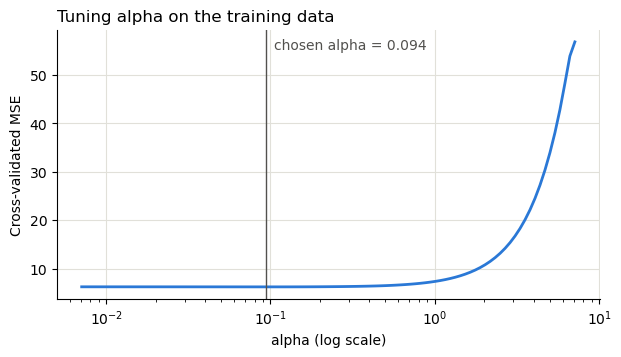

Chosen alpha: 0.094
LASSO train R2 = 0.893, RMSE = 2.46
LASSO test  R2 = 0.750, RMSE = 3.31


In [7]:
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=1, max_iter=50000)).fit(X_train, y_train)
cv = lasso[-1]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cv.alphas_, cv.mse_path_.mean(axis=1), color=BLUE, lw=2)
ax.axvline(cv.alpha_, color=INK, lw=1)
ax.annotate(f"chosen alpha = {cv.alpha_:.3f}", (cv.alpha_, ax.get_ylim()[1]), xytext=(6, -14),
            textcoords="offset points", color=INK)
ax.set_xscale("log")
ax.set(xlabel="alpha (log scale)", ylabel="Cross-validated MSE", title="Tuning alpha on the training data")
plt.show()

print("Chosen alpha: %.3f" % cv.alpha_)
print("LASSO train R2 = %.3f, RMSE = %.2f" % scores(lasso, X_train, y_train))
print("LASSO test  R2 = %.3f, RMSE = %.2f" % scores(lasso, X_test, y_test))

The error is nearly flat for small `alpha` and climbs quickly once `alpha` passes about 1, so the exact choice barely matters here.

- **Too small:** the model is close to OLS. Unlike in Ames, this costs almost nothing, because three inputs leave little room to fit noise.
- **Too large:** the useful `x3` coefficient is shrunk too far, so the model underfits.
- **The result on this dataset:** LASSO and OLS match to three decimals on both training $R^2$ (0.893) and test $R^2$ (0.750).

## 3c. Plot the LASSO coefficients

Each coefficient is the change in predicted `y` for 1 SD more of that input.

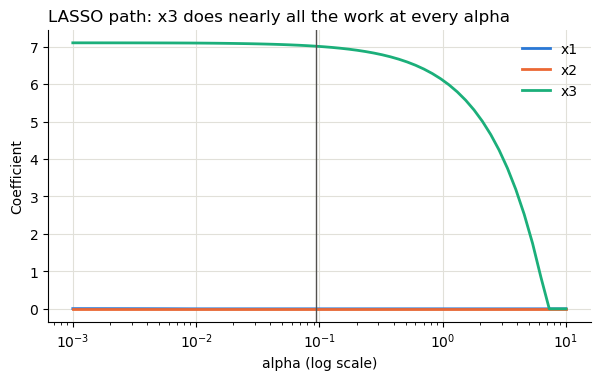

Coefficients at the smallest alpha on the path:
x1    0.006
x2    0.000
x3    7.101


In [8]:
# tol is tightened here. With exactly collinear inputs, the default tol lets a cold-started Lasso stop
# early at small alpha, far from the true minimum. LassoCV avoids this by warm-starting along its path.
alphas = np.logspace(-3, 1, 60)
path = pd.DataFrame([Lasso(alpha=a, max_iter=1000000, tol=1e-8).fit(Z_train, y_train).coef_ for a in alphas],
                    index=alphas, columns=INPUTS)
lasso_coef = pd.Series(lasso[-1].coef_, index=INPUTS)

fig, ax = plt.subplots(figsize=(7, 3.8))
for term, color in zip(INPUTS, [BLUE, ORANGE, GREEN]):
    ax.plot(path.index, path[term], color=color, lw=2, label=term)
ax.axvline(cv.alpha_, color=INK, lw=1)
ax.set_xscale("log"); ax.legend()
ax.set(xlabel="alpha (log scale)", ylabel="Coefficient", title="LASSO path: x3 does nearly all the work at every alpha")
plt.show()

print("Coefficients at the smallest alpha on the path:")
print(path.iloc[0].round(3).to_string())

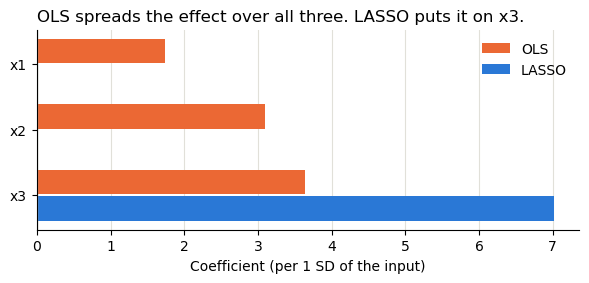

      OLS  LASSO
x1  1.735  0.000
x2  3.099  0.000
x3  3.633  7.011


In [9]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ypos = np.arange(3)[::-1]
ax.barh(ypos + 0.2, ols_coef, height=0.38, color=ORANGE, label="OLS")
ax.barh(ypos - 0.2, lasso_coef, height=0.38, color=BLUE, label="LASSO")
ax.set_yticks(ypos, INPUTS); ax.axvline(0, color=GRAY, lw=1); ax.grid(axis="y", visible=False); ax.legend()
ax.set(xlabel="Coefficient (per 1 SD of the input)", title="OLS spreads the effect over all three. LASSO puts it on x3.")
plt.show()

print(pd.DataFrame({"OLS": ols_coef, "LASSO": lasso_coef}).round(3).to_string())

- **The path:** `x3` is the only input with a visible coefficient. It enters at `alpha` of about 7 and grows to about 7.1 as `alpha` falls. The `x1` and `x2` lines stay at about 0, on top of each other.
- **The chosen model:** at `alpha` = 0.094, LASSO gives (0, 0, 7.011), keeping 1 of 3 inputs. OLS gives (1.735, 3.099, 3.633), which keeps all three. Their test $R^2$ is the same.

LASSO's answer is close to the `no x2` row in Part 3a, the solution with the smallest sum of absolute values.

# Part 4. Compare OLS and tuned LASSO

This repeats the procedure from Part 2 on 50 simulated datasets, with `alpha` retuned on each one.

In [10]:
rows, ols_coefs, lasso_coefs = [], {}, {}
for seed in range(1, 51):
    X_s, y_s = simulate(seed=seed)
    Xa, Xb, ya, yb = train_test_split(X_s, y_s, test_size=0.3, random_state=seed)
    m_ols = make_pipeline(StandardScaler(), LinearRegression()).fit(Xa, ya)
    m_lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=1, max_iter=50000)).fit(Xa, ya)

    ols_coefs[seed] = pd.Series(m_ols[-1].coef_, index=INPUTS)
    lasso_coefs[seed] = pd.Series(m_lasso[-1].coef_, index=INPUTS)
    rows.append({"seed": seed,
                 "ols_train": scores(m_ols, Xa, ya)[0], "lasso_train": scores(m_lasso, Xa, ya)[0],
                 "ols_r2": scores(m_ols, Xb, yb)[0], "lasso_r2": scores(m_lasso, Xb, yb)[0],
                 "ols_rmse": scores(m_ols, Xb, yb)[1], "lasso_rmse": scores(m_lasso, Xb, yb)[1],
                 "alpha": m_lasso[-1].alpha_, "kept": (m_lasso[-1].coef_ != 0).sum()})
res = pd.DataFrame(rows).set_index("seed")
ols_coefs, lasso_coefs = pd.DataFrame(ols_coefs), pd.DataFrame(lasso_coefs)

table = pd.DataFrame({
    "median test R2": [res.ols_r2.median(), res.lasso_r2.median()],
    "worst test R2": [res.ols_r2.min(), res.lasso_r2.min()],
    "median test RMSE": [res.ols_rmse.median(), res.lasso_rmse.median()],
    "avg train-test gap": [(res.ols_train - res.ols_r2).mean(), (res.lasso_train - res.lasso_r2).mean()],
}, index=["OLS", "LASSO"]).round(3)
print(table.to_string())
print("\nLASSO higher test R2 on", (res.lasso_r2 > res.ols_r2).sum(), "of 50 datasets")
print("Largest |difference in test R2|: %.3f" % (res.lasso_r2 - res.ols_r2).abs().max())
print("Median alpha: %.3f   Average inputs kept: %.1f of 3" % (res.alpha.median(), res.kept.mean()))

       median test R2  worst test R2  median test RMSE  avg train-test gap
OLS             0.839          0.658              3.10               0.024
LASSO           0.838          0.659              3.11               0.024

LASSO higher test R2 on 24 of 50 datasets
Largest |difference in test R2|: 0.017
Median alpha: 0.081   Average inputs kept: 1.8 of 3


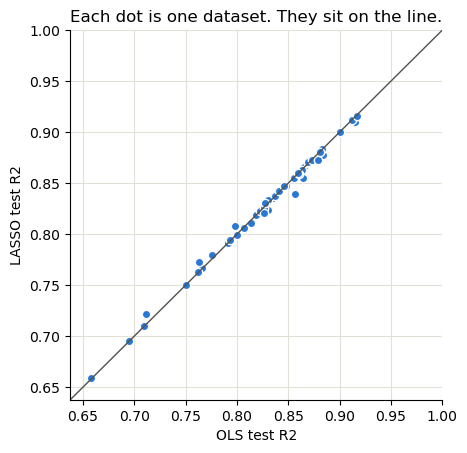

In [11]:
# Each dot is one simulated dataset. Set the limits to fit your results.
lim = [min(res.ols_r2.min(), res.lasso_r2.min()) - 0.02, 1]
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.scatter(res.ols_r2, res.lasso_r2, color=BLUE, s=36, edgecolor="#fcfcfb", lw=1)
ax.plot(lim, lim, color=INK, lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set(xlabel="OLS test R2", ylabel="LASSO test R2", title="Each dot is one dataset. They sit on the line.")
plt.show()

There's no winner. LASSO won 24 of 50 datasets, about what a coin flip would give, and the two test $R^2$ values never differ by more than 0.017.

# Part 5. Summarize the variables in the two models

Prediction is a tie, so the interesting difference is in the coefficients. This table summarizes them over the 50 datasets.

In [12]:
summary = pd.DataFrame({"ols_mean": ols_coefs.mean(axis=1), "ols_sd": ols_coefs.std(axis=1),
                        "lasso_mean": lasso_coefs.mean(axis=1), "lasso_sd": lasso_coefs.std(axis=1),
                        "pct_kept": (lasso_coefs != 0).mean(axis=1) * 100})
print(summary.round(3).to_string())
print("\nLargest LASSO |x1| or |x2| coefficient when kept: %.3f" %
      lasso_coefs.loc[["x1", "x2"]].abs().to_numpy().max())

# Convert the averages back to the original units: divide by each input's true SD (1, 1 and sqrt(13))
sds = pd.Series([1, 1, 13 ** 0.5], index=INPUTS)
print("\nAverage coefficients in original units (per 1 unit of the input):")
print(pd.DataFrame({"OLS": summary.ols_mean / sds, "LASSO": summary.lasso_mean / sds}).round(3).to_string())

    ols_mean  ols_sd  lasso_mean  lasso_sd  pct_kept
x1     1.979   0.400       0.210     0.316      46.0
x2     2.896   0.385       0.203     0.362      32.0
x3     3.530   0.325       6.625     0.725     100.0

Largest LASSO |x1| or |x2| coefficient when kept: 1.438

Average coefficients in original units (per 1 unit of the input):
      OLS  LASSO
x1  1.979  0.210
x2  2.896  0.203
x3  0.979  1.837


- **OLS** keeps all three inputs every time and splits the effect among them. In original units, its averages are close to $2x_1 + 3x_2 + 1x_3$, and that expression equals $4x_1 + 6x_2$.
- **LASSO** always keeps `x3`, with an average of about 1.84 per unit. That's close to $y = 5 + 2x_3$, pulled a little toward 0 by the penalty.
- **Small extras:** LASSO keeps `x1` on 46% of datasets and `x2` on 32%, with coefficients averaging about 0.2 across all datasets (the largest is 1.44). Noise makes the best-fitting direction differ slightly from `x3`, so a small amount of another input can help. At the chosen `alpha`, LASSO kept 1.8 of 3 inputs on average.
- **LASSO isn't clearly more stable here.** Its `x1` and `x2` coefficients vary a little less than OLS's (SD 0.32 and 0.36 vs 0.40 and 0.39), but its `x3` coefficient varies about twice as much (0.725 vs 0.325), because that one coefficient carries the whole effect. In Ames, LASSO's coefficients were far more stable, so this isn't automatic.

**Does LASSO always choose `x3`?** No. The next table changes the coefficients in `y` and lowers the noise to SD 1, so the pattern is easy to see. Each triple is the coefficients on (`x1`, `x2`, `x3`), per 1 SD of the input.

In [13]:
# Theory for standardized inputs: z3 = w1*z1 + w2*z2, with w = (2, 3) / sqrt(13)
w1, w2 = 2 / 13 ** 0.5, 3 / 13 ** 0.5


def limits(b1, b2):
    """With no noise and huge n: the OLS answer (smallest sum of squares) and the LASSO answer (smallest sum of |b|)."""
    line = lambda c: np.array([b1 - w1 * c, b2 - w2 * c, c])
    corners = [line(c) for c in (0, b1 / w1, b2 / w2)]
    return line((b1 * w1 + b2 * w2) / 2), min(corners, key=lambda b: np.abs(b).sum())


rows = []
for b1, b2 in [(4, 6), (4, 0), (1, 1)]:
    ols_est, lasso_est = [], []
    for seed in range(1, 51):
        X_s, y_s = simulate(seed=seed, b1=b1, b2=b2, noise_sd=1)
        Xa, _, ya, _ = train_test_split(X_s, y_s, test_size=0.3, random_state=seed)
        ols_est.append(make_pipeline(StandardScaler(), LinearRegression()).fit(Xa, ya)[-1].coef_)
        lasso_est.append(make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=1, max_iter=50000)).fit(Xa, ya)[-1].coef_)
    ols_lim, lasso_lim = limits(b1, b2)
    label = f"y = {b1}x1" + (f" + {b2}x2" if b2 else "")
    fmt = lambda b: "(" + ", ".join(f"{v:.2f}" for v in np.asarray(b) + 0.0) + ")"
    rows.append({"true model": label, "OLS theory": fmt(ols_lim), "OLS average": fmt(np.mean(ols_est, axis=0)),
                 "LASSO theory": fmt(lasso_lim), "LASSO average": fmt(np.mean(lasso_est, axis=0)),
                 "LASSO % kept": np.mean(np.array(lasso_est) != 0, axis=0).__mul__(100).round().astype(int).tolist()})
print(pd.DataFrame(rows).set_index("true model").to_string())

                        OLS theory          OLS average        LASSO theory        LASSO average   LASSO % kept
true model                                                                                                     
y = 4x1 + 6x2   (2.00, 3.00, 3.61)   (1.94, 2.94, 3.55)  (0.00, 0.00, 7.21)   (0.07, 0.07, 6.93)  [46, 32, 100]
y = 4x1        (3.38, -0.92, 1.11)  (3.30, -0.91, 1.05)  (4.00, 0.00, 0.00)  (3.81, -0.05, 0.03)  [100, 30, 34]
y = 1x1 + 1x2   (0.62, 0.42, 0.69)   (0.61, 0.40, 0.67)  (0.33, 0.00, 1.20)   (0.35, 0.00, 1.13)   [98, 0, 100]


The theory columns come from the rules in Part 6, and the 50-dataset averages land close to them.

- **`y = 4x1 + 6x2`:** this equals $2x_3$, so LASSO uses `x3`.
- **`y = 4x1`:** LASSO correctly finds `x1`. OLS gives nonzero coefficients to `x2` (−0.91) and `x3` (1.05), even though `y` is made from `x1` alone. Their `x2` parts cancel, and what's left is just more `x1`.
- **`y = x1 + x2`:** LASSO drops `x2` on **all 50 datasets**, even though the formula for `y` uses it, and uses `x1` and `x3` instead. That isn't a mistake, because $x_1 + x_2 = \tfrac{1}{3}x_1 + \tfrac{1}{3}x_3$ exactly.

That last row is the main caution: **a dropped input may still matter.** LASSO drops `x2` because `x3` already carries its information, at lower penalty cost. In the same row, the `x3` coefficient grows from 0.67 in OLS to 1.13 in LASSO, so LASSO doesn't simply shrink everything.

# Part 6. Explain why the models agree on prediction and differ on coefficients

**Why they predict alike.** Every OLS solution gives the same predictions, so the choice among them doesn't affect fit. And with only 2 independent columns and 70 training rows, OLS has little room to overfit: its average train-test gap is just 0.024, the same as LASSO's. LASSO's advantage in Ames came from cutting the variance of a 207-column model with many thinly supported columns. Here there's little variance to cut, so the penalty has nothing to gain.

**Why they pick different coefficients.** Both must choose one point from the same line of equally good solutions, and they measure size differently. The chart traces that line for the Part 3 dataset, labeled by the `x3` coefficient.

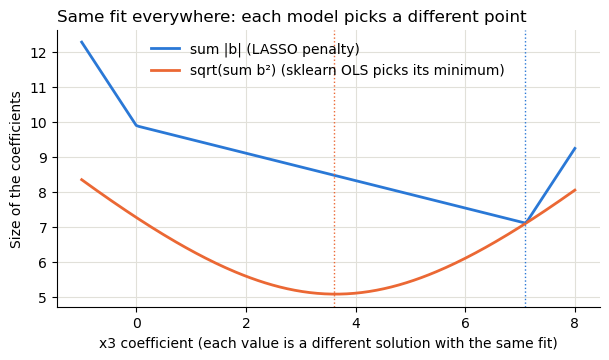

Smallest sum |b| at x3 coefficient = 7.10;  smallest sum b^2 at x3 coefficient = 3.61


In [14]:
grid = np.linspace(-1, 8, 200)
sols = np.array([solution_with_x3(c) for c in grid])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(grid, np.abs(sols).sum(axis=1), color=BLUE, lw=2, label="sum |b| (LASSO penalty)")
ax.plot(grid, np.sqrt((sols ** 2).sum(axis=1)), color=ORANGE, lw=2, label="sqrt(sum b²) (sklearn OLS picks its minimum)")
best_l1 = grid[np.abs(sols).sum(axis=1).argmin()]
best_l2 = grid[(sols ** 2).sum(axis=1).argmin()]
ax.axvline(best_l1, color=BLUE, lw=1, ls=":"); ax.axvline(best_l2, color=ORANGE, lw=1, ls=":")
ax.legend()
ax.set(xlabel="x3 coefficient (each value is a different solution with the same fit)", ylabel="Size of the coefficients",
       title="Same fit everywhere: each model picks a different point")
plt.show()
print("Smallest sum |b| at x3 coefficient = %.2f;  smallest sum b^2 at x3 coefficient = %.2f" % (best_l1, best_l2))

Every point along the bottom axis has the same fit, so only the size of the coefficients separates them.

- **`sklearn` OLS** takes the lowest point of the smooth curve, at an `x3` coefficient of 3.61, with the effect shared among all three inputs.
- **LASSO** heads for the lowest point of the other curve, at 7.10. That curve has sharp corners exactly where a coefficient reaches 0, which is why LASSO produces exact zeros. Its penalty also shrinks the result slightly, to 7.01.

**Using the rules for the theory columns.** On standardized inputs with no noise, $z_3 = 0.555z_1 + 0.832z_2$, so `y = 4x1 + 6x2` can be written two ways:

| Written with | Coefficients | Sum of absolute values | Sum of squares |
|:--|:--|--:|--:|
| `x1` and `x2` only | (4, 6, 0) | 10 | 52 |
| `x3` only | (0, 0, 7.21) | **7.21** | 52 |
| All three, split evenly | (2, 3, 3.61) | 8.61 | **26** |

Moving part of the way between the first two rows lowers the sum of squares, since squaring rewards spreading the effect around, so OLS's choice lands halfway. The absolute-value penalty has no such reward, and `x3` alone is cheapest, so LASSO goes all the way there.

**How this connects to "smaller coefficients go to 0 first".** That rule applies only when inputs are uncorrelated. Here the OLS coefficients aren't even unique, so their sizes can't decide the order. What matters is how closely each input tracks the part of `y` not yet explained.

# Takeaways

- **LASSO doesn't always beat OLS.** On these three inputs, the two tied on prediction (median test $R^2$ 0.839 vs 0.838). A penalty helps when a model has variance to cut.
- **Exact redundancy breaks interpretation, not prediction.** OLS has infinitely many solutions with identical predictions, so don't read its coefficients as separate effects.
- **LASSO picks a simple description, not necessarily the true formula.** It may drop an input that `y` depends on, when another input can carry the same information at a lower penalty.
- **Check the rank of your inputs.** It takes one line, and in Ames it revealed the same problem: `GrLivArea` is the exact sum of three other columns.